# Influência de K na silhueta — Engenharia Civil, CPC 2023

## Pergunta

O Experimento A1 (FE-CPC4, K=4) obteve silhueta de 0,2996 no treino e 0,3098 no teste. Este notebook investiga como o número de grupos altera esse valor e se uma silhueta maior leva a análises melhores no estudo.

## Principais resultados

| Pergunta | Resposta |
|---|---|
| A silhueta muda com K? | Sim. No A1, ela é maior em K=2 (0,342 no teste), mantém-se em K=3 e K=4 (0,294 e 0,298) e cai continuamente a partir de K=5. |
| Maior silhueta significa grupos melhores? | Não. Dados simulados sem grupos também têm silhueta mais alta em K=2. Descontada essa referência, o melhor K no A1 é K=4, com K=3 muito próximo. |
| K altera a estabilidade? | Sim. K=4 é o mais estável no A1 (ARI 0,948). A partir de K=6, o ARI médio fica abaixo de 0,80. |
| K altera a interpretação? | Sim. K=2 separa quase só Enade e IDD, K=3 acrescenta Condições de Formação e K=4 acrescenta Corpo Docente. K=5 ou mais apenas subdivide esses perfis. |
| K altera a conclusão sobre a PUC-Rio? | Pouco. O grupo de alto Enade e IDD se mantém, e a diferença em Regime de Trabalho fica entre −2,28 e −2,46 pontos de K=2 a K=6. |

**Decisão:** manter o A1 com K=4 como análise principal e usar K=3 como análise de sensibilidade. Os grupos devem ser apresentados como segmentos de uma distribuição contínua, e não como tipos naturais de curso.

## Desenho do experimento

- **Base:** os mesmos 451 cursos da área 5710.
- **Divisões:** as mesmas 30 divisões 80/20 do notebook 03 (sementes 42 a 71).
- **Modelo:** K-means com `random_state=42` e `n_init=20`, com transformações ajustadas somente no treino.
- **Valores de K:** 2 a 10 nos cenários A0, A1 e A2, totalizando 810 execuções.
- **Avaliação:** silhueta, Davies–Bouldin, inércia, referência sem grupos, estabilidade (ARI), variância explicada e posição da PUC-Rio.

A execução completa levou de 6 a 25 minutos nos testes, conforme a carga do computador. A Célula 9 é a mais demorada. Os resultados são gravados em `resultados_k/`. Os números citados nos textos vêm desta execução, que é reproduzível porque as sementes são fixas.

## 1. Preparação e conferência

A rotina reutiliza os mesmos dados, funções e parâmetros do notebook 03. A Célula 4 confere se o Experimento A1 é reproduzido antes de avançar para a varredura.

In [1]:
# Célula 1 — Importações e parâmetros da varredura

import itertools
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from scipy.stats import norm, rankdata
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    davies_bouldin_score,
    silhouette_samples,
    silhouette_score
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler

# Mesmos parâmetros do notebook 03
SEMENTES = list(range(42, 72))
ESTADO_KMEANS = 42
N_INIT = 20

# Valores de K avaliados
VALORES_K = list(range(2, 11))

# K utilizado em cada cenário do notebook 03
K_ORIGINAL = {"A0": 4, "A1": 4, "A2": 2}

NOMES_CENARIOS = {
    "A0": "A0 — 8 indicadores",
    "A1": "A1 — 4 dimensões",
    "A2": "A2 — RobustScaler + PCA"
}

# Pasta de saída
pasta_k = Path("resultados_k")
pasta_figuras = pasta_k / "figuras"
pasta_figuras.mkdir(parents=True, exist_ok=True)

# Identidade visual dos gráficos
COR_REAL = "#2a78d6"
COR_GAUSS = "#eb6834"
COR_COPULA = "#1baf7a"
COR_TEXTO = "#52514e"
COR_GRADE = "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.edgecolor": COR_GRADE,
    "axes.labelcolor": COR_TEXTO,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": COR_GRADE,
    "grid.linewidth": 0.7,
    "xtick.color": COR_TEXTO,
    "ytick.color": COR_TEXTO,
    "legend.frameon": False
})


def salvar_figura(fig, nome):
    fig.savefig(
        pasta_figuras / nome,
        dpi=300,
        bbox_inches="tight"
    )


def marcar_k_original(ax, k):
    ax.axvline(k, color=COR_TEXTO, linestyle=":", linewidth=1.2)


print(f"Valores de K: {VALORES_K}")
print(f"Sementes: {SEMENTES[0]} a {SEMENTES[-1]}")
print(
    "Total de execuções planejadas: "
    f"{len(SEMENTES) * len(VALORES_K) * len(NOMES_CENARIOS)}"
)

Valores de K: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Sementes: 42 a 71
Total de execuções planejadas: 810


In [2]:
# Célula 2 — Carregar a base e selecionar Engenharia Civil

arquivo = Path("dados/processados/base_analitica_1907_cursos.csv")

df = pd.read_csv(arquivo, sep=None, engine="python")

# Corrigir o caractere invisível (BOM) nos nomes das colunas
df.columns = df.columns.str.replace("﻿", "", regex=False).str.strip()

indicadores_2023 = [
    "Enade_2023",
    "IDD_2023",
    "Mestres_2023",
    "Doutores_2023",
    "Regime_Trabalho_2023",
    "Organizacao_Didatica_2023",
    "Infraestrutura_2023",
    "Oportunidades_2023"
]

df_civil = df[
    pd.to_numeric(df["Area_2023"], errors="coerce") == 5710
].copy()

puc_civil = df_civil[
    pd.to_numeric(df_civil["Código do Curso"], errors="coerce") == 29445
]

pos_puc_civil = df_civil.index.get_loc(puc_civil.index[0])

print("Cursos de Engenharia Civil:", len(df_civil))
print("Valores ausentes nos indicadores:",
      df_civil[indicadores_2023].isna().sum().sum())
print("Registros da PUC-Rio:", len(puc_civil))

Cursos de Engenharia Civil: 451
Valores ausentes nos indicadores: 0
Registros da PUC-Rio: 1


In [3]:
# Célula 3 — Funções de preparação dos cenários

# Mesma construção das quatro dimensões do notebook 03
def criar_dimensoes_cpc(base):
    resultado = pd.DataFrame(index=base.index)

    resultado["ENADE"] = base["Enade_2023"]
    resultado["IDD"] = base["IDD_2023"]

    resultado["Condicoes_Formacao"] = (
        7.5 * base["Organizacao_Didatica_2023"]
        + 5.0 * base["Infraestrutura_2023"]
        + 2.5 * base["Oportunidades_2023"]
    ) / 15.0

    resultado["Corpo_Docente"] = (
        7.5 * base["Mestres_2023"]
        + 15.0 * base["Doutores_2023"]
        + 7.5 * base["Regime_Trabalho_2023"]
    ) / 30.0

    return resultado


def preparar_cenario(cenario, treino, teste, todos):
    """Ajusta as transformações somente no treino e aplica às demais bases."""

    if cenario == "A0":
        bases = [b[indicadores_2023] for b in (treino, teste, todos)]
        scaler = StandardScaler()
    elif cenario == "A1":
        bases = [criar_dimensoes_cpc(b) for b in (treino, teste, todos)]
        scaler = StandardScaler()
    else:
        bases = [criar_dimensoes_cpc(b) for b in (treino, teste, todos)]
        scaler = RobustScaler()

    X_treino = scaler.fit_transform(bases[0])
    X_teste = scaler.transform(bases[1])
    X_todos = scaler.transform(bases[2])

    # PCA somente no cenário A2
    if cenario == "A2":
        pca = PCA(n_components=2)
        X_treino = pca.fit_transform(X_treino)
        X_teste = pca.transform(X_teste)
        X_todos = pca.transform(X_todos)

    return X_treino, X_teste, X_todos


def ajustar_kmeans(X, k):
    modelo = KMeans(
        n_clusters=k,
        random_state=ESTADO_KMEANS,
        n_init=N_INIT
    )
    modelo.fit(X)
    return modelo

In [4]:
# Célula 4 — Conferir se a rotina reproduz o Experimento A1 do notebook 03

df_treino, df_teste = train_test_split(
    df_civil,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

X_treino_A1, X_teste_A1, X_todos_A1 = preparar_cenario(
    "A1", df_treino, df_teste, df_civil
)

modelo_A1 = ajustar_kmeans(X_treino_A1, 4)

grupos_treino_A1 = modelo_A1.labels_
grupos_teste_A1 = modelo_A1.predict(X_teste_A1)

conferencia = pd.DataFrame({
    "Notebook 03": [0.2996, 0.3098, 1.1199, 1.0416],
    "Esta rotina": [
        silhouette_score(X_treino_A1, grupos_treino_A1),
        silhouette_score(X_teste_A1, grupos_teste_A1),
        davies_bouldin_score(X_treino_A1, grupos_treino_A1),
        davies_bouldin_score(X_teste_A1, grupos_teste_A1)
    ]
}, index=[
    "Silhueta treino",
    "Silhueta teste",
    "Davies–Bouldin treino",
    "Davies–Bouldin teste"
])

print("EXPERIMENTO A1 — FE-CPC4, K=4")
print("-" * 42)
display(conferencia.round(4))

print("Tamanho dos grupos no treinamento:",
      np.bincount(grupos_treino_A1).tolist())
print("Tamanho dos grupos no teste:",
      np.bincount(grupos_teste_A1, minlength=4).tolist())

EXPERIMENTO A1 — FE-CPC4, K=4
------------------------------------------


,Notebook 03,Esta rotina
Silhueta treino,0.2996,0.2996
Silhueta teste,0.3098,0.3098
Davies–Bouldin treino,1.1199,1.1199
Davies–Bouldin teste,1.0416,1.0416


Tamanho dos grupos no treinamento: [68, 107, 77, 108]
Tamanho dos grupos no teste: [22, 22, 19, 28]


A rotina reproduz exatamente as métricas e os tamanhos de grupos do Experimento A1. Portanto, as comparações seguintes partem do mesmo experimento.

## 2. Como K altera a silhueta

Para cada K, os grupos são ajustados no treino e os cursos de teste são atribuídos aos centróides, como no notebook 03. Os resultados são a média das 30 divisões.

In [5]:
# Célula 5 — Varredura de K nos três cenários e nas 30 divisões

inicio = time.time()

resultados_k = []

# Grupos atribuídos aos 451 cursos em cada execução
grupos_451 = {}

for semente in SEMENTES:

    indices_treino, indices_teste = train_test_split(
        df_civil.index,
        test_size=0.20,
        random_state=semente,
        shuffle=True
    )

    treino = df_civil.loc[indices_treino]
    teste = df_civil.loc[indices_teste]

    for cenario in NOMES_CENARIOS:

        X_treino, X_teste, X_todos = preparar_cenario(
            cenario, treino, teste, df_civil
        )

        for k in VALORES_K:

            modelo = ajustar_kmeans(X_treino, k)

            grupos_treino = modelo.labels_
            grupos_teste = modelo.predict(X_teste)
            grupos_todos = modelo.predict(X_todos)

            grupos_451[(cenario, k, semente)] = grupos_todos

            # Silhueta individual dos 451 cursos
            silhuetas = silhouette_samples(X_todos, grupos_todos)

            # Posição da PUC-Rio em relação ao seu grupo
            grupo_puc = grupos_todos[pos_puc_civil]
            no_grupo = grupos_todos == grupo_puc

            distancias = np.linalg.norm(
                X_todos - modelo.cluster_centers_[grupos_todos],
                axis=1
            )

            resultados_k.append({
                "Semente": semente,
                "Cenario": cenario,
                "K": k,
                "Silhueta_treino": silhouette_score(
                    X_treino, grupos_treino
                ),
                "Silhueta_teste": silhouette_score(
                    X_teste, grupos_teste
                ),
                "DB_treino": davies_bouldin_score(
                    X_treino, grupos_treino
                ),
                "DB_teste": davies_bouldin_score(
                    X_teste, grupos_teste
                ),
                "Inercia_treino": modelo.inertia_,
                "Menor_grupo_treino": np.bincount(grupos_treino).min(),
                "Grupos_no_teste": len(np.unique(grupos_teste)),
                "Pct_silhueta_negativa": 100 * (silhuetas < 0).mean(),
                "PUC_tamanho_grupo": no_grupo.sum(),
                "PUC_silhueta": silhuetas[pos_puc_civil],
                "PUC_percentil_distancia": 100 * np.mean(
                    distancias[no_grupo] <= distancias[pos_puc_civil]
                )
            })

log_k = pd.DataFrame(resultados_k)

print(f"Execuções registradas: {len(log_k)}")
print(f"Tempo: {time.time() - inicio:.0f} s")

Execuções registradas: 810
Tempo: 92 s


In [6]:
# Célula 6 — Resumo por cenário e K (média das 30 divisões)

metricas_k = {
    "Silhueta_treino": "mean",
    "Silhueta_teste": ["mean", "std"],
    "DB_teste": "mean",
    "Menor_grupo_treino": "mean",
    "Grupos_no_teste": "min",
    "Pct_silhueta_negativa": "mean"
}

resumo_k = log_k.groupby(["Cenario", "K"]).agg(metricas_k)

resumo_k.columns = [
    "Silhueta_treino",
    "Silhueta_teste",
    "Silhueta_teste_dp",
    "DB_teste",
    "Menor_grupo_treino",
    "Grupos_no_teste_min",
    "Pct_silhueta_negativa"
]

print("RESUMO POR K — MÉDIA DAS 30 DIVISÕES")
print("-" * 45)

for cenario in NOMES_CENARIOS:
    print(f"\n{NOMES_CENARIOS[cenario]}")
    display(resumo_k.loc[cenario].round(3))

RESUMO POR K — MÉDIA DAS 30 DIVISÕES
---------------------------------------------

A0 — 8 indicadores


,Silhueta_treino,Silhueta_teste,Silhueta_teste_dp,DB_teste,Menor_grupo_treino,Grupos_no_teste_min,Pct_silhueta_negativa
K,,,,,,,
2,0.234,0.226,0.026,1.624,153.067,2,2.055
3,0.266,0.258,0.024,1.298,81.333,3,3.481
4,0.272,0.263,0.021,1.247,62.167,4,4.730
5,0.253,0.234,0.018,1.347,48.700,5,4.893
6,0.240,0.216,0.019,1.392,32.100,6,4.893
7,0.224,0.190,0.020,1.449,27.833,7,4.974
8,0.215,0.174,0.018,1.440,23.667,8,5.625
9,0.210,0.158,0.023,1.467,17.700,9,5.403
10,0.202,0.143,0.023,1.452,15.533,10,5.684



A1 — 4 dimensões


,Silhueta_treino,Silhueta_teste,Silhueta_teste_dp,DB_teste,Menor_grupo_treino,Grupos_no_teste_min,Pct_silhueta_negativa
K,,,,,,,
2,0.340,0.342,0.031,1.087,106.167,2,1.286
3,0.300,0.294,0.022,1.234,79.633,3,1.419
4,0.305,0.298,0.023,1.091,69.800,4,0.916
5,0.276,0.258,0.025,1.163,59.767,5,1.944
6,0.268,0.232,0.021,1.195,46.900,6,1.840
7,0.258,0.227,0.021,1.175,43.233,7,2.498
8,0.250,0.204,0.026,1.241,28.867,8,2.919
9,0.243,0.182,0.024,1.264,25.933,9,3.792
10,0.239,0.171,0.023,1.281,23.100,10,4.065



A2 — RobustScaler + PCA


,Silhueta_treino,Silhueta_teste,Silhueta_teste_dp,DB_teste,Menor_grupo_treino,Grupos_no_teste_min,Pct_silhueta_negativa
K,,,,,,,
2,0.450,0.454,0.035,0.850,108.800,2,0.599
3,0.407,0.403,0.030,0.874,81.467,3,1.050
4,0.387,0.367,0.029,0.861,68.900,4,1.611
5,0.377,0.355,0.023,0.853,54.267,5,1.220
6,0.363,0.326,0.027,0.914,40.333,6,1.596
7,0.368,0.329,0.031,0.874,35.567,7,1.722
8,0.360,0.310,0.030,0.881,29.200,8,1.863
9,0.356,0.300,0.028,0.890,21.733,8,2.269
10,0.359,0.291,0.036,0.885,15.833,9,2.313


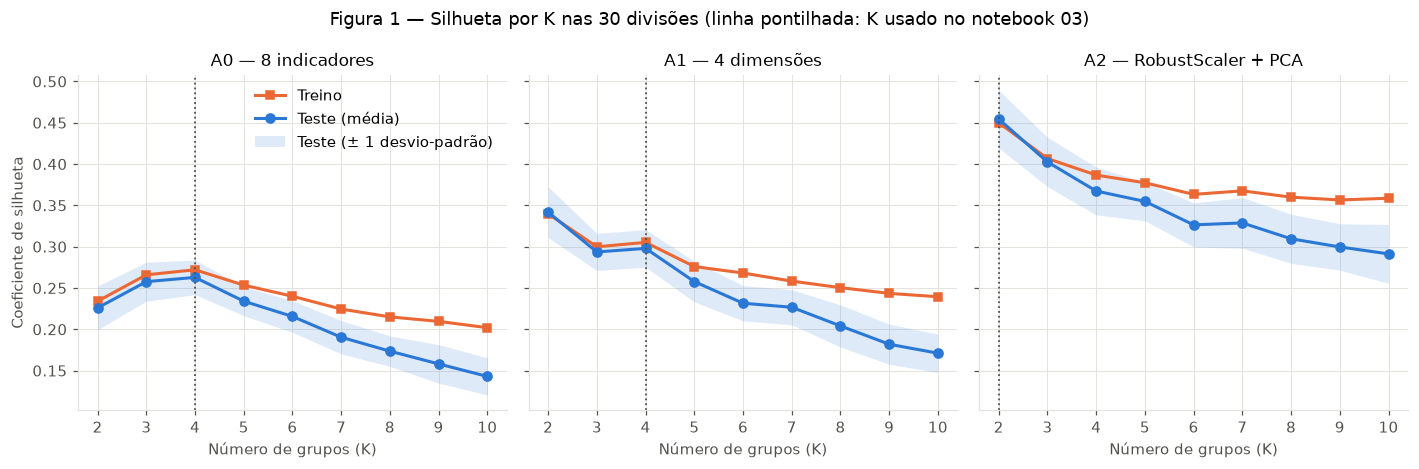

In [7]:
# Célula 7 — Figura 1: silhueta em função de K

fig, eixos = plt.subplots(
    1, 3, figsize=(13, 4.3), sharey=True
)

for ax, cenario in zip(eixos, NOMES_CENARIOS):

    dados = resumo_k.loc[cenario]

    ax.plot(
        dados.index, dados["Silhueta_treino"],
        color=COR_GAUSS, linewidth=2, marker="s",
        markersize=5, label="Treino"
    )

    ax.plot(
        dados.index, dados["Silhueta_teste"],
        color=COR_REAL, linewidth=2, marker="o",
        markersize=6, label="Teste (média)"
    )

    ax.fill_between(
        dados.index,
        dados["Silhueta_teste"] - dados["Silhueta_teste_dp"],
        dados["Silhueta_teste"] + dados["Silhueta_teste_dp"],
        color=COR_REAL, alpha=0.15, linewidth=0,
        label="Teste (± 1 desvio-padrão)"
    )

    marcar_k_original(ax, K_ORIGINAL[cenario])

    ax.set_title(NOMES_CENARIOS[cenario])
    ax.set_xlabel("Número de grupos (K)")
    ax.set_xticks(VALORES_K)

eixos[0].set_ylabel("Coeficiente de silhueta")
eixos[0].legend(loc="upper right")

fig.suptitle(
    "Figura 1 — Silhueta por K nas 30 divisões "
    "(linha pontilhada: K usado no notebook 03)",
    fontsize=12
)

plt.tight_layout()
salvar_figura(fig, "figura_1_silhueta_por_k.png")
plt.show()

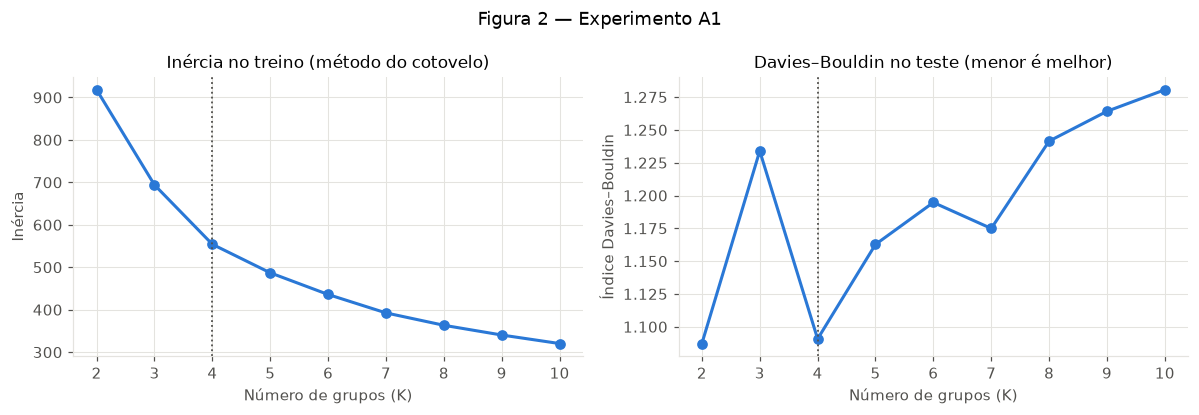

In [8]:
# Célula 8 — Figura 2: cotovelo e Davies–Bouldin no Experimento A1

resumo_A1 = (
    log_k[log_k["Cenario"] == "A1"]
    .groupby("K")[["Inercia_treino", "DB_teste"]]
    .mean()
)

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8))

eixos[0].plot(
    resumo_A1.index, resumo_A1["Inercia_treino"],
    color=COR_REAL, linewidth=2, marker="o", markersize=6
)
eixos[0].set_title("Inércia no treino (método do cotovelo)")
eixos[0].set_ylabel("Inércia")

eixos[1].plot(
    resumo_A1.index, resumo_A1["DB_teste"],
    color=COR_REAL, linewidth=2, marker="o", markersize=6
)
eixos[1].set_title("Davies–Bouldin no teste (menor é melhor)")
eixos[1].set_ylabel("Índice Davies–Bouldin")

for ax in eixos:
    marcar_k_original(ax, 4)
    ax.set_xlabel("Número de grupos (K)")
    ax.set_xticks(VALORES_K)

fig.suptitle("Figura 2 — Experimento A1", fontsize=12)

plt.tight_layout()
salvar_figura(fig, "figura_2_cotovelo_davies_bouldin_A1.png")
plt.show()

### Leitura

- **A1:** a silhueta no teste é 0,342 em K=2, 0,294 em K=3 e 0,298 em K=4. A partir daí, cai até 0,171 em K=10.
- **A0:** o máximo ocorre em K=4 (0,263). **A2:** o máximo ocorre em K=2 (0,454).
- **Generalização:** treino e teste ficam próximos até K=4 no A1. A distância aumenta com K, chegando a 0,068 em K=10, o que sugere que grupos adicionais se ajustam mais ao treino.
- **Variabilidade:** o valor 0,3098 do notebook 03 é uma das 30 divisões. A média do A1 com K=4 é 0,298, com desvio-padrão de 0,023.
- **Cotovelo:** a inércia cai 24% ao passar de K=2 para K=3, 20% de K=3 para K=4 e 12% de K=4 para K=5. O cotovelo é suave, mas coerente com K=4.
- **Davies–Bouldin:** K=2 (1,087) e K=4 (1,091) ficam praticamente empatados, e K=3 é pior (1,234).

Pela silhueta isolada, K=2 seria a escolha. A próxima seção mostra por que essa leitura é insuficiente.

## 3. Silhueta de referência: quanto aparece mesmo sem grupos?

O K-means sempre divide os dados, mesmo quando eles formam uma única nuvem. Por isso, a silhueta foi comparada com a obtida em duas bases simuladas sem grupos, geradas a partir de cada conjunto de treino:

- **Gaussiana:** mesma média e covariância dos dados reais.
- **Cópula gaussiana:** mesma distribuição de cada variável e mesmas correlações. É a referência mais exigente, pois preserva características como o acúmulo de notas no teto. Entre os 451 cursos, 43,5% têm nota máxima em Regime de Trabalho e 37,9% em Mestres.

O **ganho** é a silhueta real menos a silhueta de referência. Quanto maior o ganho, mais a estrutura encontrada supera o que surgiria sem grupos.

In [9]:
# Célula 9 — Silhueta de referência em dados sem grupos

def gerar_referencias(X, gerador):
    """Gera duas bases sem grupos, com o mesmo tamanho de X."""

    n, p = X.shape

    # Referência 1: nuvem gaussiana com a mesma média e covariância
    gaussiana = gerador.multivariate_normal(
        X.mean(axis=0),
        np.cov(X, rowvar=False),
        size=n
    )

    # Referência 2: cópula gaussiana, que mantém a distribuição
    # observada de cada variável e as correlações entre elas
    escores = np.apply_along_axis(
        lambda coluna: norm.ppf(rankdata(coluna) / (n + 1)),
        0,
        X
    )

    latente = gerador.multivariate_normal(
        np.zeros(p),
        np.corrcoef(escores, rowvar=False),
        size=n
    )

    probabilidades = norm.cdf(latente)

    copula = np.column_stack([
        np.quantile(X[:, j], probabilidades[:, j])
        for j in range(p)
    ])

    return gaussiana, copula


inicio = time.time()

resultados_ref = []

for semente in SEMENTES:

    indices_treino, indices_teste = train_test_split(
        df_civil.index,
        test_size=0.20,
        random_state=semente,
        shuffle=True
    )

    treino = df_civil.loc[indices_treino]
    teste = df_civil.loc[indices_teste]

    for cenario in NOMES_CENARIOS:

        X_treino, _, _ = preparar_cenario(
            cenario, treino, teste, df_civil
        )

        gerador = np.random.default_rng(semente)
        gaussiana, copula = gerar_referencias(X_treino, gerador)

        for k in VALORES_K:

            modelo_gauss = ajustar_kmeans(gaussiana, k)
            modelo_copula = ajustar_kmeans(copula, k)

            resultados_ref.append({
                "Semente": semente,
                "Cenario": cenario,
                "K": k,
                "Ref_gaussiana": silhouette_score(
                    gaussiana, modelo_gauss.labels_
                ),
                "Ref_copula": silhouette_score(
                    copula, modelo_copula.labels_
                )
            })

log_ref = pd.DataFrame(resultados_ref).merge(
    log_k[["Semente", "Cenario", "K", "Silhueta_treino"]],
    on=["Semente", "Cenario", "K"]
)

# Ganho: silhueta real menos a silhueta obtida sem grupos
log_ref["Ganho_gaussiana"] = (
    log_ref["Silhueta_treino"] - log_ref["Ref_gaussiana"]
)
log_ref["Ganho_copula"] = (
    log_ref["Silhueta_treino"] - log_ref["Ref_copula"]
)

resumo_ref = log_ref.groupby(["Cenario", "K"])[[
    "Silhueta_treino",
    "Ref_gaussiana",
    "Ganho_gaussiana",
    "Ref_copula",
    "Ganho_copula"
]].mean()

print(f"Tempo: {time.time() - inicio:.0f} s")

for cenario in NOMES_CENARIOS:
    print(f"\n{NOMES_CENARIOS[cenario]}")
    display(resumo_ref.loc[cenario].round(3))

Tempo: 246 s

A0 — 8 indicadores


,Silhueta_treino,Ref_gaussiana,Ganho_gaussiana,Ref_copula,Ganho_copula
K,,,,,
2,0.234,0.209,0.025,0.217,0.017
3,0.266,0.202,0.064,0.212,0.054
4,0.272,0.180,0.092,0.209,0.063
5,0.253,0.173,0.080,0.197,0.056
6,0.240,0.170,0.070,0.187,0.053
7,0.224,0.171,0.053,0.184,0.040
8,0.215,0.167,0.048,0.184,0.032
9,0.210,0.163,0.047,0.179,0.030
10,0.202,0.161,0.041,0.179,0.023



A1 — 4 dimensões


,Silhueta_treino,Ref_gaussiana,Ganho_gaussiana,Ref_copula,Ganho_copula
K,,,,,
2,0.340,0.285,0.055,0.304,0.036
3,0.300,0.233,0.066,0.256,0.044
4,0.305,0.227,0.078,0.257,0.048
5,0.276,0.229,0.047,0.248,0.028
6,0.268,0.228,0.040,0.243,0.025
7,0.258,0.225,0.033,0.241,0.017
8,0.250,0.226,0.025,0.237,0.013
9,0.243,0.226,0.018,0.235,0.009
10,0.239,0.224,0.015,0.233,0.007



A2 — RobustScaler + PCA


,Silhueta_treino,Ref_gaussiana,Ganho_gaussiana,Ref_copula,Ganho_copula
K,,,,,
2,0.450,0.392,0.058,0.452,-0.002
3,0.407,0.329,0.078,0.374,0.033
4,0.387,0.342,0.045,0.372,0.015
5,0.377,0.337,0.041,0.367,0.010
6,0.363,0.339,0.024,0.362,0.002
7,0.368,0.337,0.030,0.361,0.006
8,0.360,0.340,0.020,0.361,-0.001
9,0.356,0.344,0.013,0.362,-0.006
10,0.359,0.344,0.015,0.359,0.000


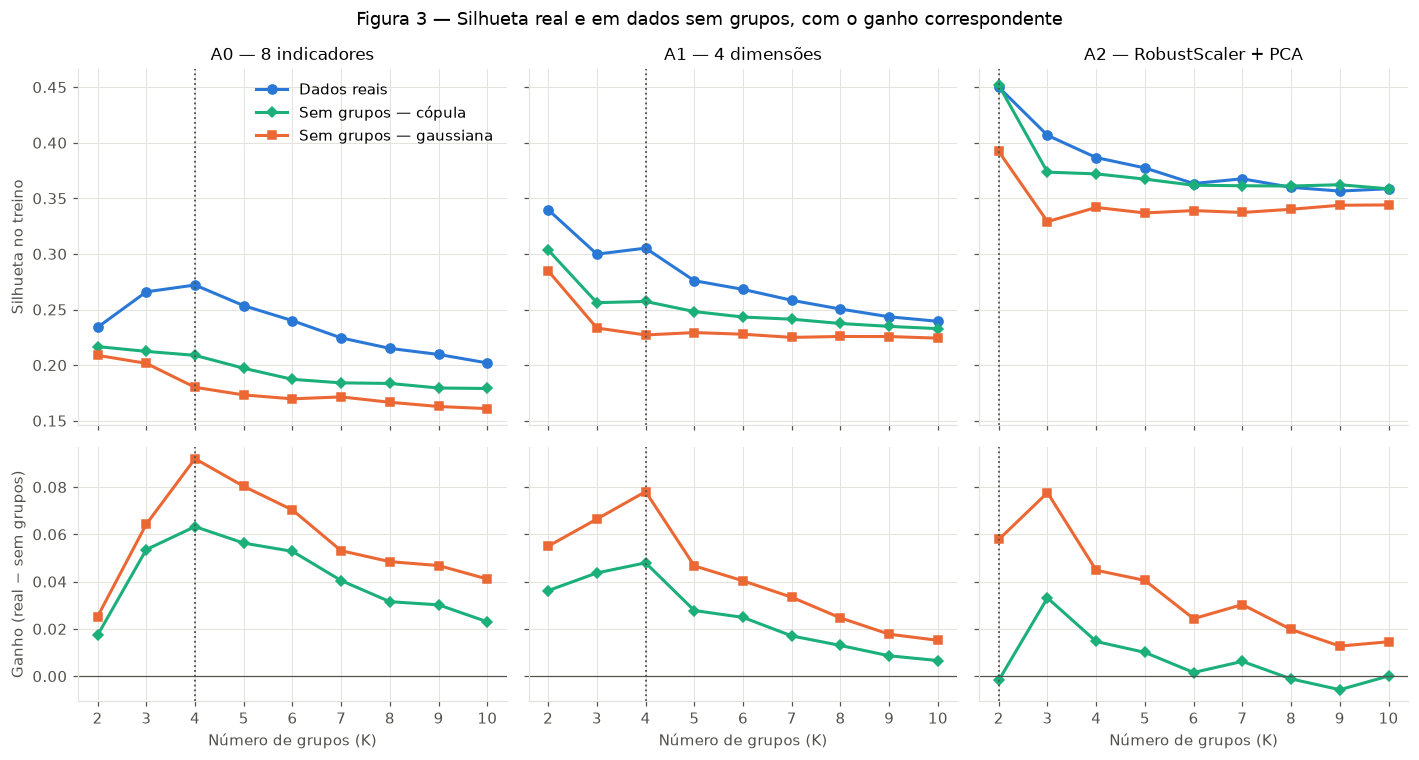

In [10]:
# Célula 10 — Figura 3: silhueta real versus dados sem grupos

fig, eixos = plt.subplots(
    2, 3, figsize=(13, 7),
    sharex=True, sharey="row",
    height_ratios=[1.4, 1]
)

for coluna, cenario in enumerate(NOMES_CENARIOS):

    dados = resumo_ref.loc[cenario]

    ax = eixos[0, coluna]

    ax.plot(
        dados.index, dados["Silhueta_treino"],
        color=COR_REAL, linewidth=2, marker="o",
        markersize=6, label="Dados reais"
    )
    ax.plot(
        dados.index, dados["Ref_copula"],
        color=COR_COPULA, linewidth=2, marker="D",
        markersize=5, label="Sem grupos — cópula"
    )
    ax.plot(
        dados.index, dados["Ref_gaussiana"],
        color=COR_GAUSS, linewidth=2, marker="s",
        markersize=5, label="Sem grupos — gaussiana"
    )

    marcar_k_original(ax, K_ORIGINAL[cenario])
    ax.set_title(NOMES_CENARIOS[cenario])

    ax = eixos[1, coluna]

    ax.plot(
        dados.index, dados["Ganho_copula"],
        color=COR_COPULA, linewidth=2, marker="D",
        markersize=5
    )
    ax.plot(
        dados.index, dados["Ganho_gaussiana"],
        color=COR_GAUSS, linewidth=2, marker="s",
        markersize=5
    )

    ax.axhline(0, color=COR_TEXTO, linewidth=0.8)
    marcar_k_original(ax, K_ORIGINAL[cenario])
    ax.set_xlabel("Número de grupos (K)")
    ax.set_xticks(VALORES_K)

eixos[0, 0].set_ylabel("Silhueta no treino")
eixos[1, 0].set_ylabel("Ganho (real − sem grupos)")
eixos[0, 0].legend(loc="upper right")

fig.suptitle(
    "Figura 3 — Silhueta real e em dados sem grupos, "
    "com o ganho correspondente",
    fontsize=12
)

plt.tight_layout()
salvar_figura(fig, "figura_3_silhueta_vs_dados_sem_grupos.png")
plt.show()

In [11]:
# Célula 11 — Comparação pareada de cada K com K=4 no Experimento A1

def comparar_com_k4(tabela, coluna):
    largura = tabela[tabela["Cenario"] == "A1"].pivot(
        index="Semente", columns="K", values=coluna
    )

    diferencas = largura.sub(largura[4], axis=0)

    return pd.DataFrame({
        "Diferenca_media": diferencas.mean(),
        "Pct_divisoes_acima_de_K4": 100 * (diferencas > 0).mean()
    }).drop(index=4)


comparacao_k4 = pd.concat({
    "Silhueta no teste": comparar_com_k4(log_k, "Silhueta_teste"),
    "Ganho (gaussiana)": comparar_com_k4(log_ref, "Ganho_gaussiana"),
    "Ganho (cópula)": comparar_com_k4(log_ref, "Ganho_copula")
}, axis=1)

print("A1 — CADA K EM RELAÇÃO A K=4, NA MESMA DIVISÃO")
print("-" * 50)
display(comparacao_k4.round(3))

A1 — CADA K EM RELAÇÃO A K=4, NA MESMA DIVISÃO
--------------------------------------------------


Silhueta no teste                          Ganho (gaussiana)  \
     Diferenca_media Pct_divisoes_acima_de_K4   Diferenca_media   
K                                                                 
2              0.044                   93.333            -0.023   
3             -0.004                   36.667            -0.012   
5             -0.040                    0.000            -0.031   
6             -0.066                    0.000            -0.038   
7             -0.071                    0.000            -0.045   
8             -0.094                    0.000            -0.053   
9             -0.116                    0.000            -0.060   
10            -0.127                    0.000            -0.063   

                             Ganho (cópula)                           
   Pct_divisoes_acima_de_K4 Diferenca_media Pct_divisoes_acima_de_K4  
K                                                                     
2                     3.333          -0.012                   26.667  
3                    13.333          -0.004                   43.333  
5                     0.000          -0.020                    6.667  
6                     3.333          -0.023                    6.667  
7                     0.000          -0.031                    0.000  
8                     0.000          -0.035                    3.333  
9                     0.000          -0.039                    3.333  
10                    0.000          -0.041                    0.000

### Leitura

- **K=2 favorece a silhueta por si só.** No A1, os dados sem grupos já alcançam 0,285 (gaussiana) e 0,304 (cópula) em K=2, contra 0,227 e 0,257 em K=4.
- **K=4 tem o maior ganho no A1:** 0,078 pela gaussiana e 0,048 pela cópula. O mesmo ocorre no A0 (0,092 e 0,063).
- **K=3 fica muito próximo de K=4 no A1.** Pela cópula, o ganho de K=3 supera o de K=4 em 13 das 30 divisões (43%), portanto não há vantagem clara entre eles.
- **K=2 e K≥5 ficam atrás de K=4.** Pela cópula, K=4 supera K=2 em 22 das 30 divisões e K=5 em 28 das 30.
- **A silhueta alta do A2 não indica grupos mais fortes.** Em K=2, a silhueta real (0,450) é igual à da cópula sem grupos (0,452), com ganho de −0,002. No A2, o maior ganho ocorre em K=3 (0,033 pela cópula).

**Consequência:** os valores 0,27, 0,30 e 0,45 de A0, A1 e A2 não devem ser usados para concluir que um cenário tem grupos melhores, pois cada espaço tem uma silhueta de base diferente.

**Cautela:** mesmo com K=4, cerca de 84% da silhueta do A1 (0,257 de 0,305) aparece na referência por cópula. O ganho é real, mas modesto.

## 4. Estabilidade dos grupos

Cada modelo classifica os 451 cursos. Em seguida, o ARI compara as classificações de todos os pares de divisões (435 comparações por K). O valor do A1 com K=4 reproduz o ARI de `resumo_estabilidade_ARI.csv` (0,948).

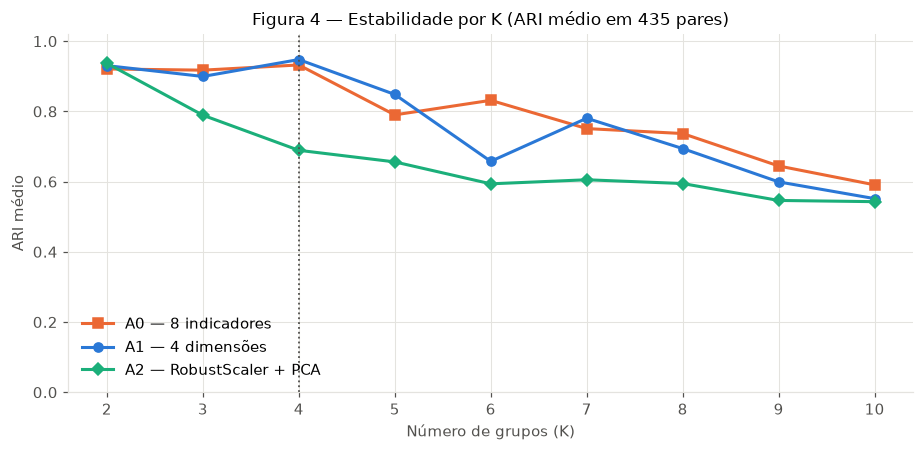

ARI — média das comparações entre divisões


Cenario,A0,A1,A2
K,,,
2,0.921,0.930,0.937
3,0.917,0.900,0.789
4,0.932,0.948,0.689
5,0.790,0.848,0.656
6,0.832,0.658,0.594
7,0.751,0.780,0.605
8,0.737,0.694,0.595
9,0.645,0.599,0.546
10,0.591,0.552,0.543


In [12]:
# Célula 12 — Estabilidade dos grupos entre as 30 divisões (435 pares)

resultados_ari = []

for cenario in NOMES_CENARIOS:
    for k in VALORES_K:

        valores = [
            adjusted_rand_score(
                grupos_451[(cenario, k, a)],
                grupos_451[(cenario, k, b)]
            )
            for a, b in itertools.combinations(SEMENTES, 2)
        ]

        resultados_ari.append({
            "Cenario": cenario,
            "K": k,
            "ARI_medio": np.mean(valores),
            "ARI_minimo": np.min(valores)
        })

resumo_ari = pd.DataFrame(resultados_ari).set_index(["Cenario", "K"])

fig, ax = plt.subplots(figsize=(8.5, 4.2))

estilos = {
    "A0": (COR_GAUSS, "s"),
    "A1": (COR_REAL, "o"),
    "A2": (COR_COPULA, "D")
}

for cenario in NOMES_CENARIOS:

    dados = resumo_ari.loc[cenario]
    cor, marcador = estilos[cenario]

    ax.plot(
        dados.index, dados["ARI_medio"],
        color=cor, linewidth=2, marker=marcador,
        markersize=6, label=NOMES_CENARIOS[cenario]
    )

marcar_k_original(ax, 4)

ax.set_title("Figura 4 — Estabilidade por K (ARI médio em 435 pares)")
ax.set_xlabel("Número de grupos (K)")
ax.set_ylabel("ARI médio")
ax.set_xticks(VALORES_K)
ax.set_ylim(0, 1.02)
ax.legend(loc="lower left")

plt.tight_layout()
salvar_figura(fig, "figura_4_estabilidade_ari_por_k.png")
plt.show()

print("ARI — média das comparações entre divisões")
display(
    resumo_ari["ARI_medio"]
    .unstack("Cenario")
    .round(3)
)

### Leitura

- **A1:** K=4 é o K mais estável (0,948), seguido de K=2 (0,930) e K=3 (0,900). Em K=6, o ARI cai para 0,658.
- **A0:** o máximo também ocorre em K=4 (0,932).
- **A2:** é o cenário mais sensível a K. O ARI cai de 0,937 em K=2 para 0,689 em K=4.

Assim, K=4 no A1 não é apenas um valor conveniente: pequenas mudanças na amostra quase não alteram seus grupos.

## 5. O que cada K acrescenta à interpretação

Esta seção avalia se os grupos são úteis para descrever os cursos. As silhuetas e os perfis usam a divisão 42, para manter os grupos do notebook 03. A variância explicada é a média das 30 divisões.

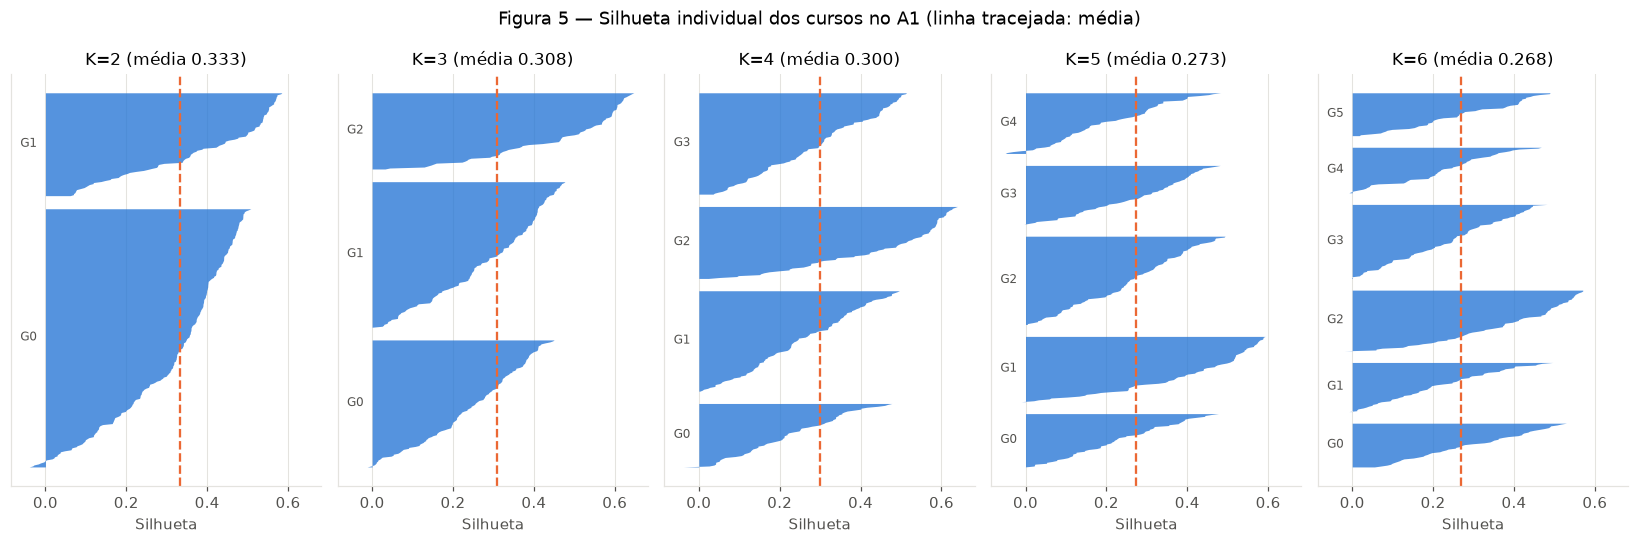

n_cursos  Silhueta_media  Pct_silhueta_negativa
K Grupo                                                 
2 0           257           0.312                  2.724
  1           103           0.384                  0.000
3 0           131           0.243                  1.527
  1           150           0.283                  0.667
  2            79           0.461                  0.000
4 0            68           0.224                  1.471
  1           107           0.250                  0.000
  2            77           0.447                  0.000
  3           108           0.291                  0.000
5 0            59           0.230                  1.695
  1            72           0.399                  1.389
  2            97           0.254                  0.000
  3            65           0.270                  1.538
  4            67           0.204                  5.970
6 0            50           0.291                  0.000
  1            56           0.211                  1.786
  2            69           0.379                  1.449
  3            84           0.231                  3.571
  4            52           0.218                  3.846
  5            49           0.271                  0.000

In [13]:
# Célula 13 — Silhueta por grupo no A1 (divisão 42, como no notebook 03)

K_DETALHE = [2, 3, 4, 5, 6]

modelos_42 = {
    k: ajustar_kmeans(X_treino_A1, k)
    for k in K_DETALHE
}

fig, eixos = plt.subplots(
    1, 5, figsize=(15, 5), sharex=True
)

linhas_coesao = []

for ax, k in zip(eixos, K_DETALHE):

    grupos = modelos_42[k].labels_
    silhuetas = silhouette_samples(X_treino_A1, grupos)
    media = silhuetas.mean()

    base = 0

    for grupo in np.unique(grupos):

        valores = np.sort(silhuetas[grupos == grupo])
        fim = base + len(valores)

        ax.fill_betweenx(
            np.arange(base, fim), 0, valores,
            color=COR_REAL, alpha=0.8, linewidth=0
        )

        ax.text(
            -0.02, (base + fim) / 2, f"G{grupo}",
            ha="right", va="center",
            fontsize=8, color=COR_TEXTO
        )

        linhas_coesao.append({
            "K": k,
            "Grupo": grupo,
            "n_cursos": len(valores),
            "Silhueta_media": valores.mean(),
            "Pct_silhueta_negativa": 100 * (valores < 0).mean()
        })

        base = fim + 12

    ax.axvline(media, color=COR_GAUSS, linestyle="--", linewidth=1.5)
    ax.set_title(f"K={k} (média {media:.3f})")
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Silhueta")

fig.suptitle(
    "Figura 5 — Silhueta individual dos cursos no A1 "
    "(linha tracejada: média)",
    fontsize=12
)

plt.tight_layout()
salvar_figura(fig, "figura_5_silhueta_por_grupo_A1.png")
plt.show()

resumo_coesao = pd.DataFrame(linhas_coesao).set_index(["K", "Grupo"])

display(resumo_coesao.round(3))

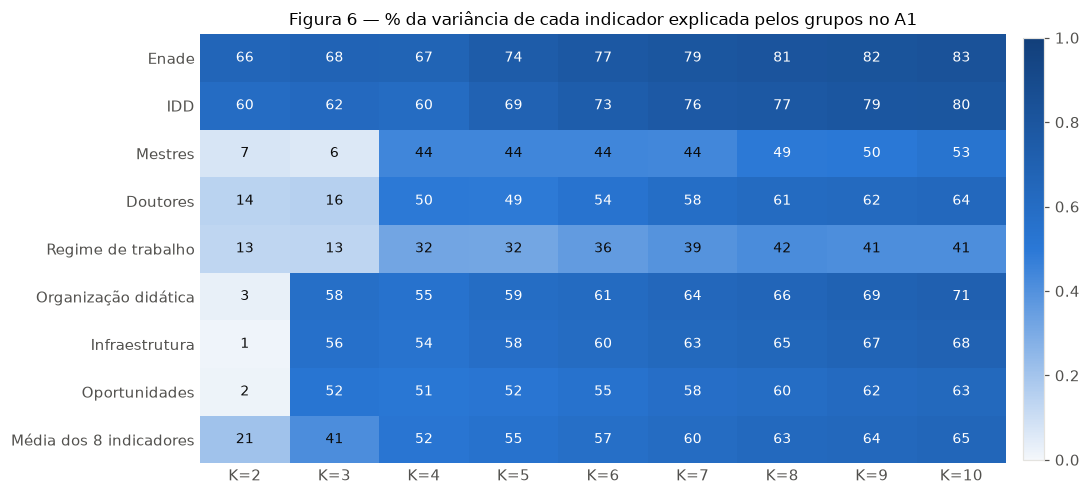

Ganho de variância explicada ao somar um grupo (pontos percentuais):
3     20.6
4     10.2
5      2.9
6      2.9
7      2.9
8      2.3
9      1.2
10     1.4


In [14]:
# Célula 14 — Quanto da variação de cada indicador os grupos explicam

def eta_quadrado(valores, grupos):
    """Proporção da variância de cada coluna explicada pelos grupos."""

    total = ((valores - valores.mean(axis=0)) ** 2).sum(axis=0)
    dentro = np.zeros(valores.shape[1])

    for grupo in np.unique(grupos):
        parte = valores[grupos == grupo]
        dentro += ((parte - parte.mean(axis=0)) ** 2).sum(axis=0)

    return 1 - dentro / total


valores_indicadores = df_civil[indicadores_2023].to_numpy(dtype=float)

nomes_indicadores = [
    "Enade", "IDD", "Mestres", "Doutores",
    "Regime de trabalho", "Organização didática",
    "Infraestrutura", "Oportunidades"
]

eta_A1 = pd.DataFrame(
    {
        k: np.mean([
            eta_quadrado(
                valores_indicadores,
                grupos_451[("A1", k, semente)]
            )
            for semente in SEMENTES
        ], axis=0)
        for k in VALORES_K
    },
    index=nomes_indicadores
)

eta_A1.loc["Média dos 8 indicadores"] = eta_A1.mean()

cmap_seq = LinearSegmentedColormap.from_list(
    "azul", ["#f4f7fb", COR_REAL, "#123f7a"]
)

fig, ax = plt.subplots(figsize=(10, 4.6))

imagem = ax.imshow(
    eta_A1.to_numpy(), cmap=cmap_seq,
    vmin=0, vmax=1, aspect="auto"
)

for i in range(eta_A1.shape[0]):
    for j in range(eta_A1.shape[1]):
        valor = eta_A1.iat[i, j]
        ax.text(
            j, i, f"{100 * valor:.0f}",
            ha="center", va="center", fontsize=9,
            color="white" if valor > 0.45 else "#0b0b0b"
        )

ax.set_xticks(range(len(VALORES_K)), [f"K={k}" for k in VALORES_K])
ax.set_yticks(range(eta_A1.shape[0]), eta_A1.index)
ax.grid(visible=False)
ax.tick_params(length=0)
for lado in ax.spines.values():
    lado.set_visible(False)

ax.set_title(
    "Figura 6 — % da variância de cada indicador explicada "
    "pelos grupos no A1"
)

fig.colorbar(imagem, ax=ax, fraction=0.025, pad=0.02)

plt.tight_layout()
salvar_figura(fig, "figura_6_variancia_explicada_A1.png")
plt.show()

ganho_eta = eta_A1.loc["Média dos 8 indicadores"].diff()

print("Ganho de variância explicada ao somar um grupo (pontos percentuais):")
print((100 * ganho_eta.dropna()).round(1).to_string())

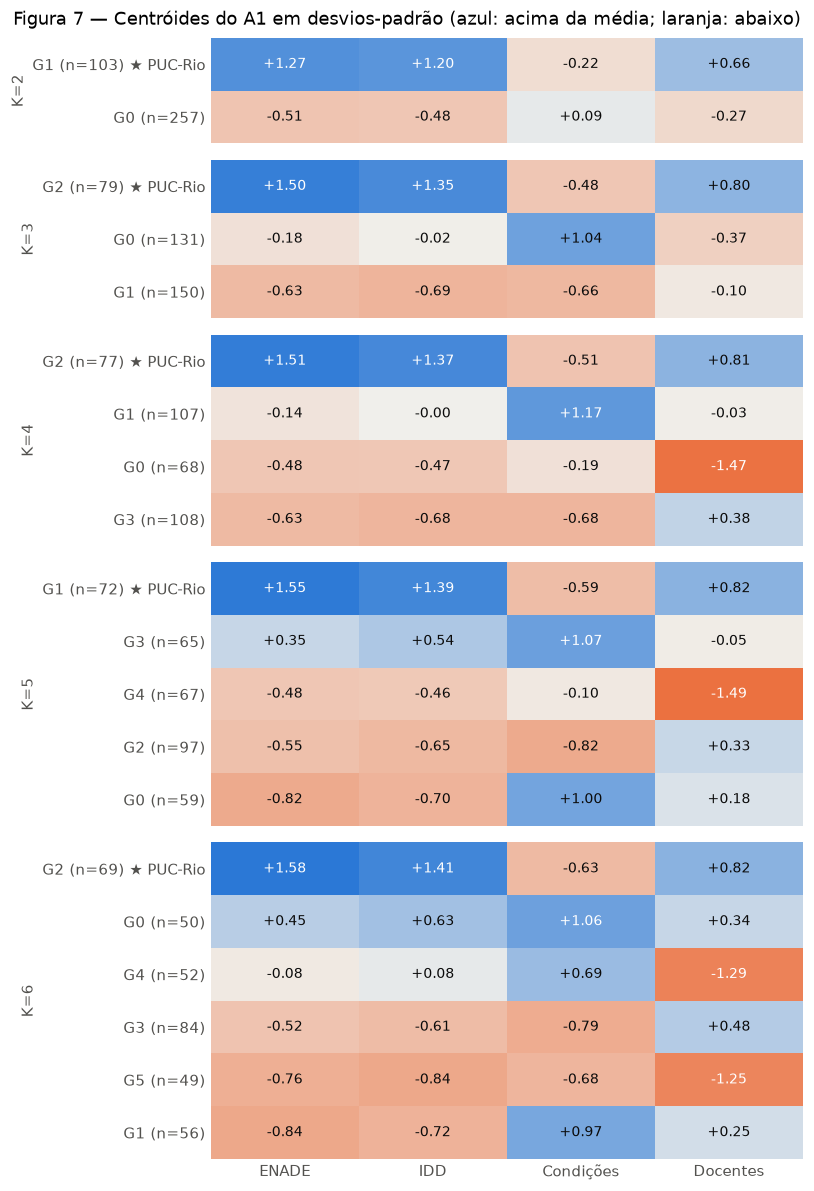

In [15]:
# Célula 15 — Perfis dos grupos no A1 (divisão 42)

dimensoes = ["ENADE", "IDD", "Condições", "Docentes"]

pos_puc_treino = df_treino.index.get_loc(puc_civil.index[0])

cmap_div = LinearSegmentedColormap.from_list(
    "divergente", [COR_GAUSS, "#f1f0ec", COR_REAL]
)

fig, eixos = plt.subplots(
    5, 1, figsize=(7.5, 11),
    gridspec_kw={"height_ratios": K_DETALHE},
    sharex=True
)

for ax, k in zip(eixos, K_DETALHE):

    modelo = modelos_42[k]
    grupos = modelo.labels_
    grupo_puc = grupos[pos_puc_treino]

    # Exibir do maior para o menor ENADE; números iguais aos do K-means
    ordem = np.argsort(-modelo.cluster_centers_[:, 0])
    centros = modelo.cluster_centers_[ordem]

    ax.imshow(
        centros, cmap=cmap_div,
        vmin=-1.6, vmax=1.6, aspect="auto"
    )

    for i in range(centros.shape[0]):
        for j in range(centros.shape[1]):
            ax.text(
                j, i, f"{centros[i, j]:+.2f}",
                ha="center", va="center", fontsize=9,
                color="white" if abs(centros[i, j]) > 1.05 else "#0b0b0b"
            )

    rotulos = [
        f"G{g} (n={(grupos == g).sum()})"
        + (" ★ PUC-Rio" if g == grupo_puc else "")
        for g in ordem
    ]

    ax.set_yticks(range(k), rotulos)
    ax.set_ylabel(f"K={k}")
    ax.grid(visible=False)
    ax.tick_params(length=0)
    for lado in ax.spines.values():
        lado.set_visible(False)

eixos[-1].set_xticks(range(4), dimensoes)

fig.suptitle(
    "Figura 7 — Centróides do A1 em desvios-padrão "
    "(azul: acima da média; laranja: abaixo)",
    fontsize=12
)

plt.tight_layout()
salvar_figura(fig, "figura_7_perfis_por_k_A1.png")
plt.show()

### Leitura

| K | O que a divisão acrescenta | Variância média explicada |
|---|---|---|
| 2 | Separa cursos por Enade e IDD; Condições de Formação quase não participam (1% a 3%). | 21% |
| 3 | Inclui Condições de Formação (52% a 58%). | 41% |
| 4 | Inclui Corpo Docente: Mestres passa de 6% para 44% e Doutores, de 16% para 50%. | 52% |
| 5 ou mais | Cada grupo adicional acrescenta menos de 3 pontos percentuais. | 55% a 65% |

Em K=4, os quatro perfis são:

- **G2 (n=77):** Enade e IDD altos e bom Corpo Docente, com Condições de Formação abaixo da média.
- **G1 (n=107):** Condições de Formação altas, com Enade e IDD próximos da média.
- **G3 (n=108):** Enade, IDD e Condições de Formação abaixo da média, com Corpo Docente acima dela.
- **G0 (n=68):** Corpo Docente bem abaixo da média.

Essa é a principal diferença entre K=3 e K=4. As silhuetas são equivalentes, mas somente K=4 identifica o perfil de fragilidade docente. A partir de K=5, os grupos novos subdividem perfis já existentes, com menor estabilidade.

Na divisão 42, a silhueta de K=3 (0,308) supera a de K=4 (0,300), enquanto na média das 30 divisões ocorre o contrário (0,300 e 0,305). Isso confirma que a diferença entre os dois é pequena demais para decidir a escolha sozinha.

## 6. Efeito de K na análise da PUC-Rio

A tabela usa as 30 divisões e os 451 cursos. A comparação com a média do grupo usa a divisão 42, como no notebook 03.

In [16]:
# Célula 16 — Efeito de K na análise da PUC-Rio (Experimento A1)

linhas_puc = []

grupo_K4 = modelos_42[4].labels_
pares_K4 = grupo_K4 == grupo_K4[pos_puc_treino]

for k in VALORES_K:

    rotulos = [grupos_451[("A1", k, s)] for s in SEMENTES]

    # Cursos que ficam com a PUC-Rio em cada divisão
    conjuntos = [
        set(np.flatnonzero(r == r[pos_puc_civil]))
        for r in rotulos
    ]

    jaccard = [
        len(a & b) / len(a | b)
        for a, b in itertools.combinations(conjuntos, 2)
    ]

    frequencia = np.mean(
        [r == r[pos_puc_civil] for r in rotulos],
        axis=0
    )

    execucoes = log_k[
        (log_k["Cenario"] == "A1") & (log_k["K"] == k)
    ]

    linhas_puc.append({
        "K": k,
        "Tamanho_grupo": execucoes["PUC_tamanho_grupo"].mean(),
        "Silhueta_PUC": execucoes["PUC_silhueta"].mean(),
        "Percentil_distancia": execucoes["PUC_percentil_distancia"].mean(),
        "Jaccard_medio": np.mean(jaccard),
        "Jaccard_minimo": np.min(jaccard),
        "Nucleo_estavel": int((frequencia == 1).sum()),
        "Cursos_variaveis": int(
            ((frequencia > 0) & (frequencia < 1)).sum()
        )
    })

efeito_puc = pd.DataFrame(linhas_puc).set_index("K")

print("A1 — POSIÇÃO DA PUC-RIO POR K (30 DIVISÕES, 451 CURSOS)")
print("-" * 55)
display(efeito_puc.round(3))

# Comparação com a média do grupo (divisão 42, como no notebook 03)
valores_puc = puc_civil[indicadores_2023].iloc[0].astype(float)

diferencas = {}

for k in K_DETALHE:

    grupos = modelos_42[k].labels_
    no_grupo = grupos == grupos[pos_puc_treino]

    diferencas[f"K={k}"] = (
        valores_puc - df_treino.loc[no_grupo, indicadores_2023].mean()
    )

diferencas_puc = pd.DataFrame(diferencas)
diferencas_puc.index = nomes_indicadores

print("\nPUC-Rio − média do seu grupo (divisão 42)")
display(diferencas_puc.round(2))

# Quanto do grupo da PUC-Rio em K=4 continua com ela
continuidade = {}

for k in K_DETALHE:

    grupos = modelos_42[k].labels_
    no_grupo = grupos == grupos[pos_puc_treino]

    continuidade[f"K={k}"] = 100 * (no_grupo & pares_K4).sum() / pares_K4.sum()

print("% do grupo da PUC-Rio em K=4 que continua no grupo dela:")
print(pd.Series(continuidade).round(1).to_string())

A1 — POSIÇÃO DA PUC-RIO POR K (30 DIVISÕES, 451 CURSOS)
-------------------------------------------------------


,Tamanho_grupo,Silhueta_PUC,Percentil_distancia,Jaccard_medio,Jaccard_minimo,Nucleo_estavel,Cursos_variaveis
K,,,,,,,
2,130.800,0.517,7.864,0.943,0.696,103,45
3,98.333,0.449,26.841,0.968,0.898,96,12
4,95.733,0.421,29.346,0.985,0.949,93,6
5,86.067,0.212,47.888,0.954,0.835,76,16
6,75.267,0.194,60.776,0.849,0.674,58,30
7,59.433,0.193,80.066,0.878,0.017,2,129
8,55.300,0.167,83.985,0.846,0.044,4,90
9,50.767,0.139,81.424,0.689,0.034,3,100
10,43.867,0.100,73.185,0.411,0.012,1,115



PUC-Rio − média do seu grupo (divisão 42)


,K=2,K=3,K=4,K=5,K=6
Enade,0.28,0.06,0.05,0.01,-0.02
IDD,0.22,0.07,0.05,0.03,0.01
Mestres,-0.30,-0.34,-0.34,-0.32,-0.31
Doutores,0.60,0.45,0.43,0.39,0.39
Regime de trabalho,-2.28,-2.45,-2.46,-2.46,-2.46
Organização didática,0.19,0.48,0.52,0.61,0.66
Infraestrutura,0.90,1.20,1.24,1.32,1.37
Oportunidades,0.60,0.77,0.78,0.83,0.84


% do grupo da PUC-Rio em K=4 que continua no grupo dela:
K=2    100.0
K=3    100.0
K=4    100.0
K=5     93.5
K=6     89.6


### Leitura

- **O grupo da PUC-Rio é robusto.** Todos os 77 cursos do seu grupo em K=4 continuam com ela em K=3 e K=2. Em K=5, são 93,5% e, em K=6, 89,6%.
- **K=4 tem os pares mais estáveis.** O Jaccard médio é 0,985, com núcleo de 93 cursos e apenas 6 variáveis, valores iguais aos de `resumo_estabilidade_PUCRio_A1.csv`. A partir de K=7, o núcleo praticamente desaparece (1 a 4 cursos).
- **A posição da PUC-Rio piora a partir de K=5.** A silhueta do curso cai de 0,421 em K=4 para 0,212 em K=5, e o percentil de distância ao centróide sobe de 29,3 para 47,9. O motivo é o surgimento de um grupo próximo, com Condições de Formação altas e Enade intermediário.
- **O achado sobre Regime de Trabalho não depende de K.** A diferença em relação ao grupo fica entre −2,28 e −2,46 pontos de K=2 a K=6.

Portanto, a conclusão principal sobre a PUC-Rio não depende da escolha exata de K. Essa escolha afeta principalmente a composição dos pares e a confiança nessa comparação.

## 7. Quadro de decisão

In [17]:
# Célula 17 — Quadro de decisão do Experimento A1

quadro_decisao = pd.DataFrame({
    "Silhueta_teste": resumo_k.loc["A1", "Silhueta_teste"],
    "Ganho_gaussiana": resumo_ref.loc["A1", "Ganho_gaussiana"],
    "Ganho_copula": resumo_ref.loc["A1", "Ganho_copula"],
    "ARI_medio": resumo_ari.loc["A1", "ARI_medio"],
    "Jaccard_PUC": efeito_puc["Jaccard_medio"],
    "Variancia_explicada_8": eta_A1.loc["Média dos 8 indicadores"],
    "Menor_grupo_treino": resumo_k.loc["A1", "Menor_grupo_treino"],
    "Pct_silhueta_negativa": resumo_k.loc["A1", "Pct_silhueta_negativa"]
})

print("QUADRO DE DECISÃO — A1")
print("-" * 40)
display(quadro_decisao.round(3))

melhor = pd.Series({
    "Maior silhueta no teste": quadro_decisao["Silhueta_teste"].idxmax(),
    "Maior ganho (gaussiana)": quadro_decisao["Ganho_gaussiana"].idxmax(),
    "Maior ganho (cópula)": quadro_decisao["Ganho_copula"].idxmax(),
    "Maior ARI": quadro_decisao["ARI_medio"].idxmax(),
    "Maior Jaccard da PUC-Rio": quadro_decisao["Jaccard_PUC"].idxmax()
})

print("K vencedor por critério:")
print(melhor.to_string())

QUADRO DE DECISÃO — A1
----------------------------------------


,Silhueta_teste,Ganho_gaussiana,Ganho_copula,ARI_medio,Jaccard_PUC,Variancia_explicada_8,Menor_grupo_treino,Pct_silhueta_negativa
2,0.342,0.055,0.036,0.930,0.943,0.208,106.167,1.286
3,0.294,0.066,0.044,0.900,0.968,0.414,79.633,1.419
4,0.298,0.078,0.048,0.948,0.985,0.517,69.800,0.916
5,0.258,0.047,0.028,0.848,0.954,0.546,59.767,1.944
6,0.232,0.040,0.025,0.658,0.849,0.575,46.900,1.840
7,0.227,0.033,0.017,0.780,0.878,0.604,43.233,2.498
8,0.204,0.025,0.013,0.694,0.846,0.627,28.867,2.919
9,0.182,0.018,0.009,0.599,0.689,0.639,25.933,3.792
10,0.171,0.015,0.007,0.552,0.411,0.653,23.100,4.065


K vencedor por critério:
Maior silhueta no teste     2
Maior ganho (gaussiana)     4
Maior ganho (cópula)        4
Maior ARI                   4
Maior Jaccard da PUC-Rio    4


### Decisão

**Manter o A1 com K=4 como análise principal.** K=2 vence somente em silhueta no teste, e K=4 vence nos demais critérios: ganho nas duas referências, ARI e Jaccard da PUC-Rio.

| Configuração | Papel no estudo | Justificativa |
|---|---|---|
| A1, K=4 | Análise principal | Maior ganho e estabilidade, com perfis interpretáveis e pares estáveis para a PUC-Rio. |
| A1, K=3 | Sensibilidade | Silhueta e ganho equivalentes, mas sem o perfil de Corpo Docente. |
| A1, K=2 | Descrição simples | Resume bem Enade e IDD, mas ignora Condições de Formação. |
| A2, K=2 | Não usar como melhor resultado | Sua silhueta alta é igual à obtida sem grupos pela cópula. |
| K≥5 | Não recomendado | Pouca informação nova e menor silhueta, ganho e estabilidade. |

### Respostas ao objetivo do estudo

**A escolha de K melhora a análise?** Sim, quando é baseada em vários critérios. Maximizar a silhueta levaria a K=2 e perderia duas das três dimensões que diferenciam os cursos. Aumentar K além de 4 reduziria a estabilidade sem acrescentar perfis realmente novos.

**O que pode ser afirmado?** Os indicadores permitem uma segmentação estável e interpretável em quatro perfis, e a PUC-Rio pertence de forma consistente ao perfil de alto Enade e IDD.

**O que não pode ser afirmado?** Que existem quatro tipos naturais de curso. Uma silhueta próxima de 0,30 está na faixa considerada fraca por Kaufman e Rousseeuw (0,26 a 0,50), e o ganho sobre a referência é modesto.

### Limitações

- As 30 divisões compartilham cursos, logo não são amostras independentes. Por isso, os resultados foram apresentados como médias e proporções de divisões, sem testes de significância.
- O ganho foi calculado no treino. As referências também foram simuladas com base nesses dados, e outras referências poderiam gerar valores diferentes.
- K=4 já vinha sendo usado no estudo, de modo que esta análise o avalia nos mesmos 451 cursos, sem uma amostra externa independente.
- Os grupos dependem do K-means, que favorece partições compactas e de tamanhos semelhantes. A comparação entre métodos está no notebook `experimentos_clustering_por_area.ipynb`.
- Os resultados descrevem o ciclo de 2023 e a Engenharia Civil. Eles não indicam causas nem devem ser generalizados para outras áreas.

## 8. Exportação

In [18]:
# Célula 18 — Exportar resultados

saidas = {
    "log_varredura_k.csv": log_k,
    "log_referencia_sem_grupos.csv": log_ref,
    "resumo_por_k.csv": resumo_k.reset_index(),
    "resumo_referencia_sem_grupos.csv": resumo_ref.reset_index(),
    "resumo_estabilidade_ari.csv": resumo_ari.reset_index(),
    "variancia_explicada_A1.csv": eta_A1.reset_index(),
    "efeito_puc_A1.csv": efeito_puc.reset_index(),
    "quadro_decisao_A1.csv": quadro_decisao.reset_index()
}

for nome, tabela in saidas.items():
    tabela.to_csv(
        pasta_k / nome,
        index=False,
        sep=";",
        decimal=",",
        encoding="utf-8-sig"
    )

print("ARQUIVOS EXPORTADOS")
print("-" * 45)

for caminho in sorted(pasta_k.rglob("*.*")):
    print(caminho)

ARQUIVOS EXPORTADOS
---------------------------------------------
resultados_k\efeito_puc_A1.csv
resultados_k\figuras\figura_1_silhueta_por_k.png
resultados_k\figuras\figura_2_cotovelo_davies_bouldin_A1.png
resultados_k\figuras\figura_3_silhueta_vs_dados_sem_grupos.png
resultados_k\figuras\figura_4_estabilidade_ari_por_k.png
resultados_k\figuras\figura_5_silhueta_por_grupo_A1.png
resultados_k\figuras\figura_6_variancia_explicada_A1.png
resultados_k\figuras\figura_7_perfis_por_k_A1.png
resultados_k\log_referencia_sem_grupos.csv
resultados_k\log_varredura_k.csv
resultados_k\quadro_decisao_A1.csv
resultados_k\resumo_estabilidade_ari.csv
resultados_k\resumo_por_k.csv
resultados_k\resumo_referencia_sem_grupos.csv
resultados_k\variancia_explicada_A1.csv
